In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from pathlib import Path

In [2]:
data_path = Path.cwd() / "../data"
os.chdir(data_path)

file_names = [p.name[:-5] for p in data_path.iterdir() if p.is_file()]
print(file_names)

data = {}
for name in file_names:
    with open(data_path / f'{name}.json', encoding='utf-8') as f:
        data[name] = json.load(f)
bus = data['bus_params']

for idx in range(len(bus[0]["energy_price_DKK_per_kWh"])):
    print(f"Hour {idx} price: ", bus[0]["energy_price_DKK_per_kWh"][idx])

#Import/Export prices
print(f'Import price: ', bus[0]['import_tariff_DKK_per_kWh'], '\nExport price: ',
 bus[0]['export_tariff_DKK_per_kWh'])

['appliance_params', 'bus_params', 'params_Q1_caseA', 'params_Q1_caseB', 'params_Q2_linear', 'params_Q2_quadratic', 'params_Q3', 'params_Q3_battery']
Hour 0 price:  1.1
Hour 1 price:  1.05
Hour 2 price:  1.0
Hour 3 price:  0.9
Hour 4 price:  0.85
Hour 5 price:  1.01
Hour 6 price:  1.05
Hour 7 price:  1.2
Hour 8 price:  1.4
Hour 9 price:  1.6
Hour 10 price:  1.5
Hour 11 price:  1.1
Hour 12 price:  1.05
Hour 13 price:  1.0
Hour 14 price:  0.95
Hour 15 price:  1.0
Hour 16 price:  1.2
Hour 17 price:  1.5
Hour 18 price:  2.1
Hour 19 price:  2.5
Hour 20 price:  2.2
Hour 21 price:  1.8
Hour 22 price:  1.4
Hour 23 price:  1.2
Import price:  0.5 
Export price:  0.4


In [3]:
P_price_per_kwh = bus[0]['energy_price_DKK_per_kWh']
export_price = bus[0]['export_tariff_DKK_per_kWh']
import_price = bus[0]['import_tariff_DKK_per_kWh']

hours_u_greater_p_imp = []
hours_u_lesser_p_exp = []

for h in range(24):
    pt_imp = P_price_per_kwh[h] + export_price
    pt_exp = P_price_per_kwh[h] - import_price

    #Consumption utility for problem 1
    u = data['appliance_params']['loads'][0]['consumption_utility_DKK_per_kWh']

    if u > pt_imp:
        hours_u_greater_p_imp.append(h)
    elif u < pt_exp:
        hours_u_lesser_p_exp.append(h)

print('Import: ', hours_u_greater_p_imp, '\n', 'Export: ', hours_u_lesser_p_exp, sep ='')

Import: [2, 3, 4, 5, 13, 14, 15]
Export: [18, 19, 20]


In [4]:
c_pv_a = data['appliance_params']['DERs'][0]['marginal_cost_DKK_per_kWh']
c_pv_b = data['appliance_params']['DERs'][1]['marginal_cost_DKK_per_kWh']
u = data['appliance_params']['loads'][0]['consumption_utility_DKK_per_kWh']

print('Case A: ', round(u - c_pv_a, 2))
print('Case B: ', round(u - c_pv_b, 2))

Case A:  0.02
Case B:  -0.04


In [5]:
min_energy = data['appliance_params']['loads'][3]['min_total_energy_per_day_kWh']

ref_lod_cap_factor = data['appliance_params']['loads'][
    3]['reference_load_capacity_factor']
max_load_kWh_per_hour = data['appliance_params']['loads'][3]['max_load_KWh_per_hour']

lt_ref = round(sum([max_load_kWh_per_hour * ref_lod_cap_factor[x]
               for x in range(len(ref_lod_cap_factor))]), 2)
print('lt_ref: ', lt_ref)

lt_ref:  32.34


In [6]:
# PV_01_A 0 -> max_power_kW
# ref_load_cap_factor_fl2l = data['appliance_params']['loads'][1]['reference_load_capacity_factor']
# ref_load_cap_factor_fl2q = data['appliance_params']['loads'][2]['reference_load_capacity_factor']
# ref_load_cap_factor_fl3 = data['appliance_params']['loads'][3]['reference_load_capacity_factor']

# max_load_kWh_per_hour = data['appliance_params']['loads'][0]['max_load_KWh_per_hour']

max_power_kW = data['appliance_params']['DERs'][0]['max_power_kW']
hourly_profile_ratio = data['appliance_params']['DERs'][0]['hourly_profile_ratio']

pv_available = [max_power_kW * r for r in hourly_profile_ratio]
print('PV hours:', [h for h in range(24) if pv_available[h] > 0])
print('Total PV:', round(sum(pv_available), 2))


for h in [18, 19]:
    p_imp = P_price_per_kwh[h] + import_price
    p_exp = P_price_per_kwh[h] - export_price
    print(f'Hour {h}: PV = {pv_available[h]:.2f} kWh, p = {P_price_per_kwh[h]:.2f}, ' 
          f'p_imp = {p_imp:.2f}, p_exp = {p_exp:.2f}')


PV hours: [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
Total PV: 26.94
Hour 18: PV = 1.50 kWh, p = 2.10, p_imp = 2.60, p_exp = 1.70
Hour 19: PV = 1.50 kWh, p = 2.50, p_imp = 3.00, p_exp = 2.10


In [7]:
import sys
sys.path.append('..')

from src.data_loader import load_question
from src.model_q2 import LinearDisutilityModel

data = load_question("Q2_linear")
results = LinearDisutilityModel(data).build().solve()

print(results)
results.hourly
results.objective
results.save("results/Q2_linear")

Set parameter Username
Set parameter LicenseID to value 2859426
Academic license - for non-commercial use only - expires 2027-09-01


status: OPTIMAL | objective: 44.31 DKK
daily totals (kWh): load=23.1, pv=26.1, import=0.0, export=3.0


## Extra Plots for Q2 b) LinearDisutility

In [8]:
import sys
sys.path.append('..')

from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import src
from src.data_loader import load_question
from src.model_q2 import LinearDisutilityModel

OUT = Path(src.__file__).resolve().parents[1] / "results" / "Q2_linear"
OUT.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, GREEN, VIOLET = "#2a78d6", "#eb6834", "#008300", "#4a3aa7"
INK, GREY = "#0b0b0b", "#898781"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "xtick.color": GREY, "ytick.color": GREY,
    "axes.labelcolor": "#52514e", "lines.linewidth": 2, "legend.frameon": False,
})


def run(data, c_L):
    """Solve the linear-disutility model for one value of c_L (DKK/kWh) and return (results, metrics)."""
    d = replace(data, linear_disutility=float(c_L))
    res = LinearDisutilityModel(d).build().solve()
    h = res.hourly
    dev = (h["dev_up"] + h["dev_down"]).sum()
    at_bound = (h["reference_load"] > 0) & (h["load"] <= d.load_min_kWh + 1e-9)
    return res, {
        "energy_kWh": h["load"].sum(),
        "procurement_DKK": res.objective - c_L * dev,
        "disutility_DKK": c_L * dev,
        "objective_DKK": res.objective,
        "abs_deviation_kWh": dev,
        "hours_at_bound": int(at_bound.sum()),
    }


data = load_question("Q2_linear")
results, base = run(data, data.linear_disutility)
hr = results.hourly
hours = hr.index.to_numpy()
p_imp = data.energy_price + data.import_tariff
p_exp = data.energy_price - data.export_tariff


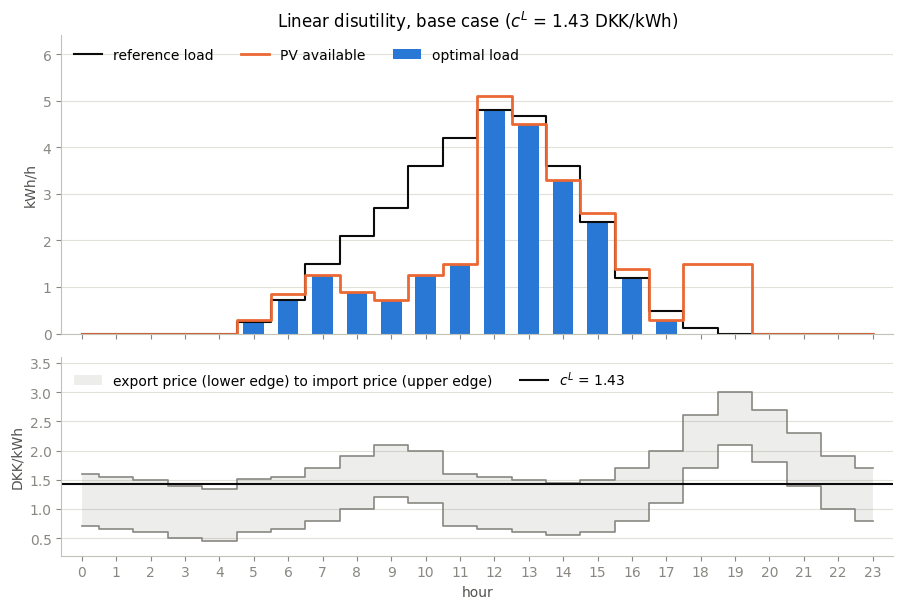

In [9]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6.2), sharex=True, height_ratios=[3, 2])

ax1.bar(hours, hr["load"], width=0.6, color=BLUE, label="optimal load")
ax1.step(hours, hr["reference_load"], where="mid", color=INK, lw=1.5, label="reference load")
ax1.step(hours, hr["pv_available"], where="mid", color=ORANGE, label="PV available")
ax1.set(ylabel="kWh/h", ylim=(0, 6.4),
        title=f"Linear disutility, base case ($c^L$ = {data.linear_disutility} DKK/kWh)")
ax1.legend(ncol=3, loc="upper left")

ax2.fill_between(hours, p_exp, p_imp, step="mid", color=GREY, alpha=0.15, lw=0,
                 label="export price (lower edge) to import price (upper edge)")
ax2.step(hours, p_imp, where="mid", color=GREY, lw=1.2)
ax2.step(hours, p_exp, where="mid", color=GREY, lw=1.2)
ax2.axhline(data.linear_disutility, color=INK, lw=1.5, label=f"$c^L$ = {data.linear_disutility}")
ax2.set(xlabel="hour", ylabel="DKK/kWh", xticks=hours, xlim=(-0.6, 23.6), ylim=(0.2, 3.6))
ax2.legend(ncol=2, loc="upper left")

fig.tight_layout()
fig.savefig(OUT / "q2b_base_case.png", dpi=150)


predicted thresholds: [1.41, 1.45, 1.5, 1.6, 1.7, 1.9, 2.0, 2.1]


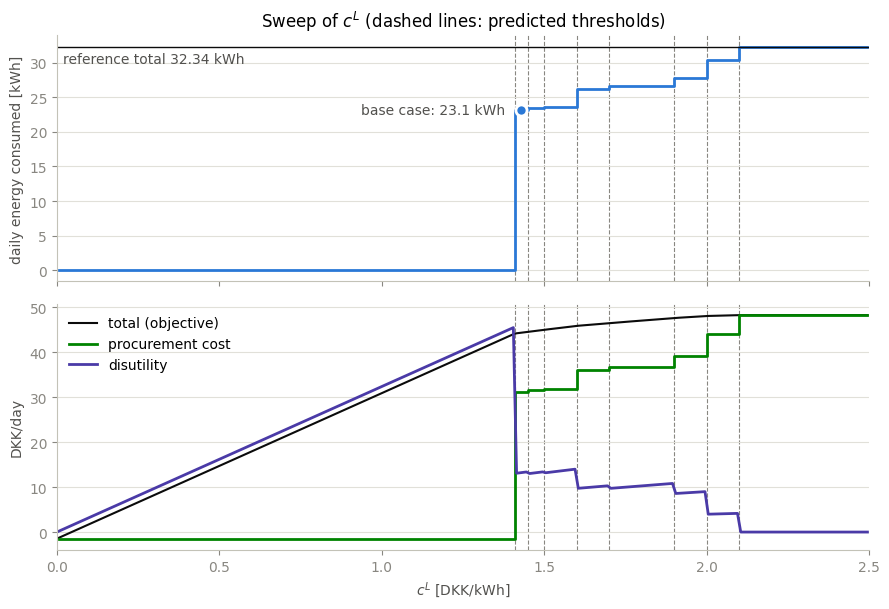

In [10]:
c_values = np.round(np.arange(0.005, 2.5, 0.01), 3)
sweep = pd.DataFrame({c: run(data, c)[1] for c in c_values}).T
sweep.index.name = "c_L"

a = np.median([p_exp, np.full(len(hours), data.pv_marginal_cost), p_imp], axis=0)
ref, pv_max = data.reference_load, data.pv_available
thresholds = sorted({float(x) for x in np.round(a[np.minimum(ref, pv_max) > 0], 2)}
                    | {float(x) for x in np.round(p_imp[ref > pv_max], 2)})
print("predicted thresholds:", thresholds)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6.2), sharex=True)
for ax in (ax1, ax2):
    for th in thresholds:
        ax.axvline(th, color=GREY, lw=0.8, ls="--", zorder=0)

ax1.plot(sweep.index, sweep["energy_kWh"], color=BLUE, drawstyle="steps-mid")
ax1.axhline(ref.sum(), color=INK, lw=1)
ax1.text(0.02, ref.sum() - 0.8, f"reference total {ref.sum():.2f} kWh", va="top", color="#52514e")
ax1.plot(data.linear_disutility, base["energy_kWh"], "o", color=BLUE, ms=8, mec="white", mew=2)
ax1.annotate(f"base case: {base['energy_kWh']:.1f} kWh", (data.linear_disutility, base["energy_kWh"]),
             xytext=(-12, 0), textcoords="offset points", ha="right", va="center", color="#52514e")
ax1.set(ylabel="daily energy consumed [kWh]", title="Sweep of $c^L$ (dashed lines: predicted thresholds)")

ax2.plot(sweep.index, sweep["objective_DKK"], color=INK, lw=1.5, label="total (objective)")
ax2.plot(sweep.index, sweep["procurement_DKK"], color=GREEN, drawstyle="steps-mid", label="procurement cost")
ax2.plot(sweep.index, sweep["disutility_DKK"], color=VIOLET, label="disutility")
ax2.set(xlabel="$c^L$ [DKK/kWh]", ylabel="DKK/day", xlim=(0, 2.5))
ax2.legend(loc="upper left")

fig.tight_layout()
fig.savefig(OUT / "q2b_sweep.png", dpi=150)


In [11]:
table = pd.DataFrame({c: run(data, c)[1] for c in [1.0, 1.43, 1.55, 1.65, 1.80, 1.95, 2.05, 2.20]}).T
table.index.name = "c_L"
table = table.astype({"hours_at_bound": int})
table.round(2)


,energy_kWh,procurement_DKK,disutility_DKK,objective_DKK,abs_deviation_kWh,hours_at_bound
c_L,,,,,,
1.00,0.00,-1.47,32.34,30.87,32.34,14
1.43,23.10,31.10,13.21,44.31,9.24,1
1.55,23.58,31.81,13.58,45.38,8.76,1
1.65,26.28,36.13,10.00,46.13,6.06,1
1.80,26.64,36.74,10.26,47.00,5.70,0
1.95,27.84,39.02,8.78,47.79,4.50,0
2.05,30.36,44.06,4.06,48.12,1.98,0
2.20,32.34,48.22,0.00,48.22,0.00,0


## Extra Plots for Q2 c) Quadratic Disutility

In [1]:
import sys
sys.path.append('..')

from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import src
from src.data_loader import load_question
from src.model_q2 import QuadraticDisutilityModel

OUT_Q = Path(src.__file__).resolve().parents[1] / "results" / "Q2_quadratic"
OUT_Q.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, GREEN, VIOLET = "#2a78d6", "#eb6834", "#008300", "#4a3aa7"
INK, GREY = "#0b0b0b", "#898781"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "xtick.color": GREY, "ytick.color": GREY,
    "axes.labelcolor": "#52514e", "lines.linewidth": 2, "legend.frameon": False,
})


def run_q(data, c_Q):
    """Solve the quadratic-disutility model for one value of c_Q (DKK/kWh^2) and return (results, metrics)."""
    d = replace(data, quadratic_disutility=float(c_Q))
    res = QuadraticDisutilityModel(d).build().solve()
    h = res.hourly
    dev = (h["reference_load"] - h["load"]).abs()
    disutility = c_Q * (dev ** 2).sum()
    at_bound = (h["reference_load"] > 0) & (h["load"] <= d.load_min_kWh + 1e-4)
    return res, {
        "energy_kWh": h["load"].sum(),
        "procurement_DKK": res.objective - disutility,
        "disutility_DKK": disutility,
        "objective_DKK": res.objective,
        "abs_deviation_kWh": dev.sum(),
        "hours_at_bound": int(at_bound.sum()),
    }


data_q = load_question("Q2_quadratic")
c_Q = data_q.quadratic_disutility
res_q, base_q = run_q(data_q, c_Q)
hr_q = res_q.hourly
hours = hr_q.index.to_numpy()
p_imp = data_q.energy_price + data_q.import_tariff
p_exp = data_q.energy_price - data_q.export_tariff
base_q


Set parameter Username
Set parameter LicenseID to value 2859426
Academic license - for non-commercial use only - expires 2027-09-01


{'energy_kWh': np.float64(22.76500727982701),
 'procurement_DKK': np.float64(32.544460266541805),
 'disutility_DKK': np.float64(7.4265647356739475),
 'objective_DKK': 39.971025002215754,
 'abs_deviation_kWh': np.float64(9.57499272023345),
 'hours_at_bound': 3}

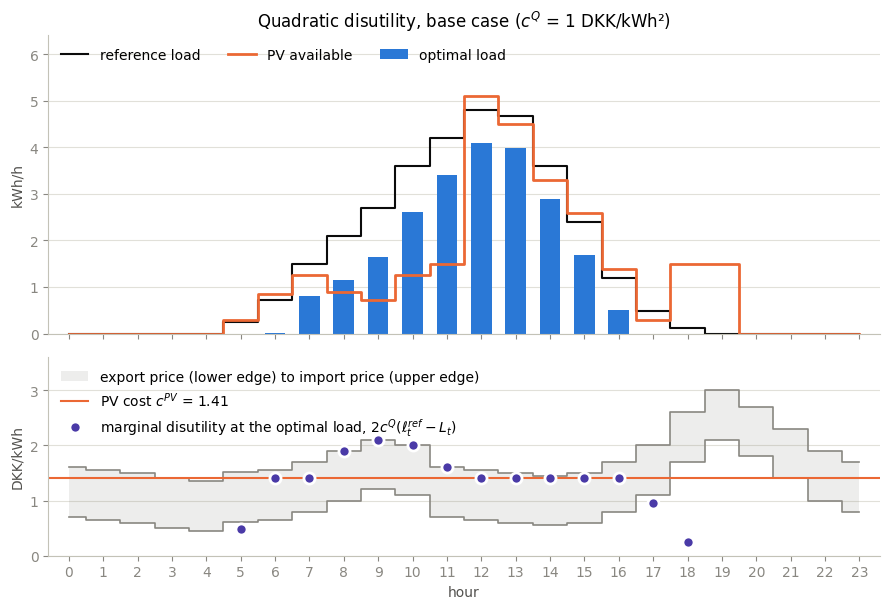

In [2]:
with_ref = (hr_q["reference_load"] > 0).to_numpy()
marginal = 2 * c_Q * (hr_q["reference_load"] - hr_q["load"]).to_numpy()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6.2), sharex=True, height_ratios=[3, 2])

ax1.bar(hours, hr_q["load"], width=0.6, color=BLUE, label="optimal load")
ax1.step(hours, hr_q["reference_load"], where="mid", color=INK, lw=1.5, label="reference load")
ax1.step(hours, hr_q["pv_available"], where="mid", color=ORANGE, label="PV available")
ax1.set(ylabel="kWh/h", ylim=(0, 6.4),
        title=f"Quadratic disutility, base case ($c^Q$ = {c_Q:g} DKK/kWh²)")
ax1.legend(ncol=3, loc="upper left")

ax2.fill_between(hours, p_exp, p_imp, step="mid", color=GREY, alpha=0.15, lw=0,
                 label="export price (lower edge) to import price (upper edge)")
ax2.step(hours, p_imp, where="mid", color=GREY, lw=1.2)
ax2.step(hours, p_exp, where="mid", color=GREY, lw=1.2)
ax2.axhline(data_q.pv_marginal_cost, color=ORANGE, lw=1.5, label=f"PV cost $c^{{PV}}$ = {data_q.pv_marginal_cost}")
ax2.plot(hours[with_ref], marginal[with_ref], "o", color=VIOLET, ms=8, mec="white", mew=2,
         label="marginal disutility at the optimal load, $2c^Q(\\ell^{ref}_t - L_t)$")
ax2.set(xlabel="hour", ylabel="DKK/kWh", xticks=hours, xlim=(-0.6, 23.6), ylim=(0, 3.6))
ax2.legend(loc="upper left")

fig.tight_layout()
fig.savefig(OUT_Q / "q2c_base_case.png", dpi=150)


In [5]:
hr_q[["reference_load", "pv_available", "load", "pv", "import", "export"]].round(3)
hr_q["import"].sum()

np.float64(4.420000005924292)

largest difference between solver and closed form: 1.9e-04 kWh
largest load above the reference: 5.3e-08 kWh
predicted start of consumption: c_Q = 0.147


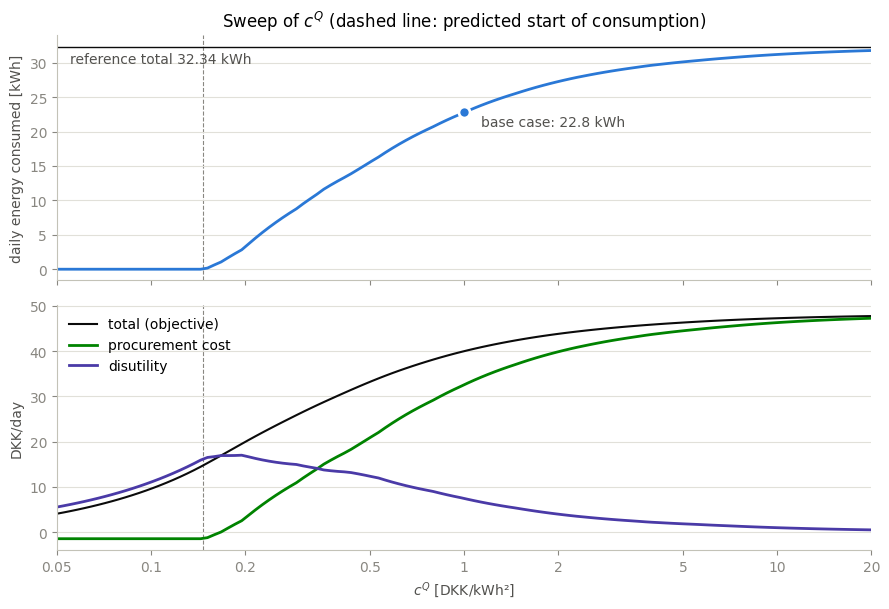

In [3]:
c_values = np.geomspace(0.05, 20, 120)
runs_q = {c: run_q(data_q, c) for c in c_values}
sweep_q = pd.DataFrame({c: metrics for c, (_, metrics) in runs_q.items()}).T
sweep_q.index.name = "c_Q"

a = np.median([p_exp, np.full(len(hours), data_q.pv_marginal_cost), p_imp], axis=0)
ref, pv_max = data_q.reference_load, data_q.pv_available
first_kink = (a[ref > 0] / (2 * ref[ref > 0])).min()


def closed_form(c):
    """Hourly loads (kWh) predicted in 2.(c).ii for a coefficient c (DKK/kWh^2)."""
    return np.clip(np.clip(pv_max, ref - p_imp / (2 * c), ref - a / (2 * c)), data_q.load_min_kWh, data_q.load_max_kWh)


gap = max(np.abs(res.hourly["load"] - closed_form(c)).max() for c, (res, _) in runs_q.items())
above = max((res.hourly["load"] - ref).max() for res, _ in runs_q.values())
print(f"largest difference between solver and closed form: {gap:.1e} kWh")
print(f"largest load above the reference: {above:.1e} kWh")
print(f"predicted start of consumption: c_Q = {first_kink:.3f}")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6.2), sharex=True)
for ax in (ax1, ax2):
    ax.axvline(first_kink, color=GREY, lw=0.8, ls="--", zorder=0)

ax1.plot(sweep_q.index, sweep_q["energy_kWh"], color=BLUE)
ax1.axhline(ref.sum(), color=INK, lw=1)
ax1.text(0.055, ref.sum() - 0.8, f"reference total {ref.sum():.2f} kWh", va="top", color="#52514e")
ax1.plot(c_Q, base_q["energy_kWh"], "o", color=BLUE, ms=8, mec="white", mew=2)
ax1.annotate(f"base case: {base_q['energy_kWh']:.1f} kWh", (c_Q, base_q["energy_kWh"]),
             xytext=(12, -2), textcoords="offset points", ha="left", va="top", color="#52514e")
ax1.set(ylabel="daily energy consumed [kWh]", title="Sweep of $c^Q$ (dashed line: predicted start of consumption)")

ax2.plot(sweep_q.index, sweep_q["objective_DKK"], color=INK, lw=1.5, label="total (objective)")
ax2.plot(sweep_q.index, sweep_q["procurement_DKK"], color=GREEN, label="procurement cost")
ax2.plot(sweep_q.index, sweep_q["disutility_DKK"], color=VIOLET, label="disutility")
ticks = [0.05, 0.1, 0.2, 0.5, 1, 2, 5, 10, 20]
ax2.set(xlabel="$c^Q$ [DKK/kWh²]", ylabel="DKK/day", xscale="log", xlim=(0.05, 20))
ax2.set_xticks(ticks, [f"{t:g}" for t in ticks])
ax2.minorticks_off()
ax2.legend(loc="upper left")

fig.tight_layout()
fig.savefig(OUT_Q / "q2c_sweep.png", dpi=150)


### Values sanity check

In [4]:
loads_q = np.array([res.hourly["load"].to_numpy() for res, _ in runs_q.values()])
imports_q = np.array([res.hourly["import"].sum() for res, _ in runs_q.values()])
dev_q = (ref - loads_q)[:, ref > 0]
predicted_at_bound = [int(((ref > 0) & (closed_form(c) <= 1e-4)).sum()) for c in c_values]
short = ref > pv_max
import_kinks = p_imp[short] / (2 * (ref - pv_max)[short])
last_kink = (a[ref > 0] / (2 * ref[ref > 0])).max()
after_last_kink = sweep_q.index > last_kink

print(f"increase of c_Q between two runs: {c_values[1] / c_values[0] - 1:.1%}")
print(f"largest change between two runs: {np.diff(sweep_q['energy_kWh']).max():.2f} kWh per day, "
      f"{np.diff(loads_q, axis=0).max():.2f} kWh in one hour")
print(f"largest decrease of an hourly load: {-np.diff(loads_q, axis=0).min():.1e} kWh")
print(f"hours at bound as predicted in every run: {(sweep_q['hours_at_bound'].to_numpy() == predicted_at_bound).all()}")
print(f"fewest hours below the reference in any run: {(dev_q > 1e-6).sum(axis=1).min()} of {(ref > 0).sum()}")
print(f"deviations at c_Q = {c_values[-1]:g}: {dev_q[-1].min():.2f} to {dev_q[-1].max():.2f} kWh")
print(f"imports start: predicted c_Q = {import_kinks.min():.3f}, first run with imports c_Q = {c_values[imports_q > 1e-3].min():.3f}")
print(f"first run above half of the reference energy: c_Q = {c_values[sweep_q['energy_kWh'] >= ref.sum() / 2].min():.3f}")
print(f"largest disutility: {sweep_q['disutility_DKK'].max():.1f} DKK at c_Q = {sweep_q['disutility_DKK'].idxmax():.3f}")
print(f"last kink: c_Q = {last_kink:.2f}; deviation times c_Q above it: "
      f"{(sweep_q['abs_deviation_kWh'] * sweep_q.index)[after_last_kink].min():.2f} to "
      f"{(sweep_q['abs_deviation_kWh'] * sweep_q.index)[after_last_kink].max():.2f}")


def loads_tight(c):
    """Hourly loads (kWh) for a coefficient c, solved with tight solver tolerances."""
    model = QuadraticDisutilityModel(replace(data_q, quadratic_disutility=float(c))).build()
    model.m.Params.BarConvTol = 1e-12
    model.m.Params.OptimalityTol = 1e-9
    model.m.Params.FeasibilityTol = 1e-9
    return model.solve().hourly["load"].to_numpy()


gap_tight = max(np.abs(loads_tight(c) - closed_form(c)).max() for c in c_values)
print(f"largest difference between solver and closed form, tight tolerances: {gap_tight:.1e} kWh")


increase of c_Q between two runs: 5.2%
largest change between two runs: 0.85 kWh per day, 0.23 kWh in one hour
largest decrease of an hourly load: 1.1e-05 kWh
hours at bound as predicted in every run: True
fewest hours below the reference in any run: 14 of 14
deviations at c_Q = 20: 0.04 to 0.05 kWh
imports start: predicted c_Q = 0.296, first run with imports c_Q = 0.306
first run above half of the reference energy: c_Q = 0.533
largest disutility: 17.0 DKK at c_Q = 0.195
last kink: c_Q = 7.08; deviation times c_Q above it: 11.50 to 11.50
largest difference between solver and closed form, tight tolerances: 8.7e-08 kWh


## Comparison Plots

In [16]:
import sys
sys.path.append('..')

from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import src
from src.data_loader import load_question
from src.model import FlexibleConsumerModel
from src.model_q2 import LinearDisutilityModel, QuadraticDisutilityModel

#OUT_D = Path(src.__file__).resolve().parents[1] / "results" / "Q2_comparison"
#OUT_D.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, AQUA, INK, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#898781"
BLUE_RAMP, ORANGE_RAMP = ["#86b6ef", "#2a78d6", "#104281"], ["#f2a07e", "#eb6834", "#8f3410"]
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "xtick.color": GREY, "ytick.color": GREY,
    "axes.labelcolor": "#52514e", "lines.linewidth": 2, "legend.frameon": False,
})

PAIRS = {"base": (1.43, 1.0), "medium": (1.65, 2.0), "high": (2.05, 5.0)}


def comparison_metrics(results, data, reference, has_disutility=True):
    """Daily metrics of one run: energies in kWh, costs in DKK. Deviations are measured against
    ``reference``; the disutility is the objective minus the procurement cost."""
    h = results.hourly
    deviation = np.abs(reference - h["load"].to_numpy())
    procurement = float(((data.energy_price + data.import_tariff) * h["import"]
                         - (data.energy_price - data.export_tariff) * h["export"]
                         + data.pv_marginal_cost * h["pv"]).sum())
    return {
        "energy_kWh": h["load"].sum(),
        "procurement_DKK": procurement,
        "disutility_DKK": results.objective - procurement if has_disutility else np.nan,
        "total_DKK": results.objective if has_disutility else np.nan,
        "abs_deviation_kWh": deviation.sum(),
        "hours_deviating": int((deviation > 1e-3).sum()),
        "largest_deviation_kWh": deviation.max(),
        "hours_at_bound": int(((reference > 0) & (h["load"] <= data.load_min_kWh + 1e-3)).sum()),
        "import_kWh": h["import"].sum(),
        "pv_unused_kWh": (data.pv_available - h["pv"]).sum(),
    }


data_q1, data_lin, data_quad = load_question("Q1_caseA"), load_question("Q2_linear"), load_question("Q2_quadratic")
reference = data_lin.reference_load

res_q1 = FlexibleConsumerModel(data_q1).build().solve()
rows = [{"scenario": "Q1", "model": "linear utility", "coefficient": data_q1.consumption_utility,
         **comparison_metrics(res_q1, data_q1, reference, has_disutility=False)}]
pair_loads = {}
for name, (c_lin, c_quad) in PAIRS.items():
    d_lin = replace(data_lin, linear_disutility=c_lin)
    d_quad = replace(data_quad, quadratic_disutility=c_quad)
    res_lin = LinearDisutilityModel(d_lin).build().solve()
    res_quad = QuadraticDisutilityModel(d_quad).build().solve()
    rows.append({"scenario": name, "model": "linear disutility", "coefficient": c_lin,
                 **comparison_metrics(res_lin, d_lin, reference)})
    rows.append({"scenario": name, "model": "quadratic disutility", "coefficient": c_quad,
                 **comparison_metrics(res_quad, d_quad, reference)})
    pair_loads[f"{name.capitalize()}: $c^L$ = {c_lin}, $c^Q$ = {c_quad:g}"] = (
        res_lin.hourly["load"].to_numpy(), res_quad.hourly["load"].to_numpy())

table_d = pd.DataFrame(rows).round(3)
#table_d.to_csv(OUT_D / "q2d_metrics.csv", index=False)
table_d


,scenario,model,coefficient,energy_kWh,procurement_DKK,disutility_DKK,total_DKK,abs_deviation_kWh,hours_deviating,largest_deviation_kWh,hours_at_bound,import_kWh,pv_unused_kWh
0,Q1,linear utility,1.43,35.940,48.785,NaN,NaN,22.080,16,6.000,1,12.000,0.000
1,base,linear disutility,1.43,23.100,31.101,13.213,44.314,9.240,9,2.700,1,0.000,0.840
2,base,quadratic disutility,1.00,22.765,32.544,7.427,39.971,9.575,14,1.050,3,4.420,5.595
3,medium,linear disutility,1.65,26.280,36.126,9.999,46.125,6.060,6,2.340,1,3.180,0.840
4,medium,quadratic disutility,2.00,27.260,39.848,3.955,43.803,5.080,14,0.525,2,6.320,3.000
5,high,linear disutility,2.05,30.360,44.058,4.059,48.117,1.980,1,1.980,0,7.140,0.840
6,high,quadratic disutility,5.00,30.110,44.476,1.822,46.298,2.230,14,0.210,1,7.715,1.545


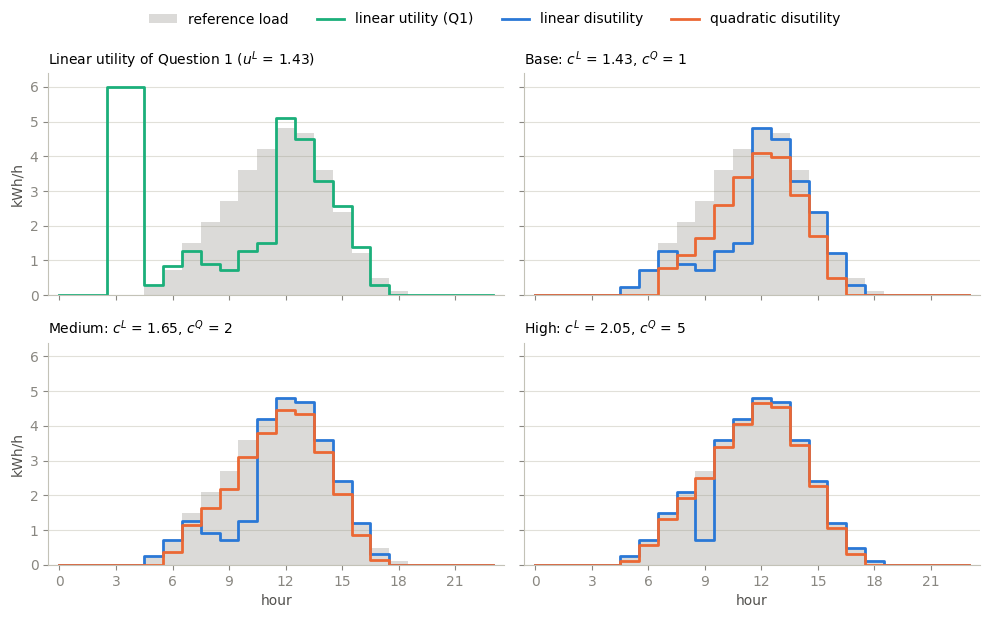

In [17]:
hours = np.arange(len(reference))
panels = [(f"Linear utility of Question 1 ($u^L$ = {data_q1.consumption_utility})",
           [(res_q1.hourly["load"].to_numpy(), AQUA, "linear utility (Q1)")])]
panels += [(title, [(lin, BLUE, "linear disutility"), (quad, ORANGE, "quadratic disutility")])
           for title, (lin, quad) in pair_loads.items()]

fig, axes = plt.subplots(2, 2, figsize=(10, 6.2), sharex=True, sharey=True)
handles = {}
for ax, (title, series) in zip(axes.flat, panels):
    handles["reference load"] = ax.fill_between(hours, reference, step="mid", color=GREY, alpha=0.3, lw=0)
    for load, color, label in series:
        handles[label], = ax.step(hours, load, where="mid", color=color)
    ax.set_title(title, loc="left", fontsize=10)
    ax.set(xticks=hours[::3], xlim=(-0.6, 23.6), ylim=(0, 6.4))
for ax in axes[:, 0]:
    ax.set_ylabel("kWh/h")
for ax in axes[-1, :]:
    ax.set_xlabel("hour")
fig.legend(handles.values(), handles.keys(), ncol=4, loc="upper center")
fig.tight_layout(rect=(0, 0, 1, 0.95))
#fig.savefig(OUT_D / "q2d_profiles.png", dpi=150)


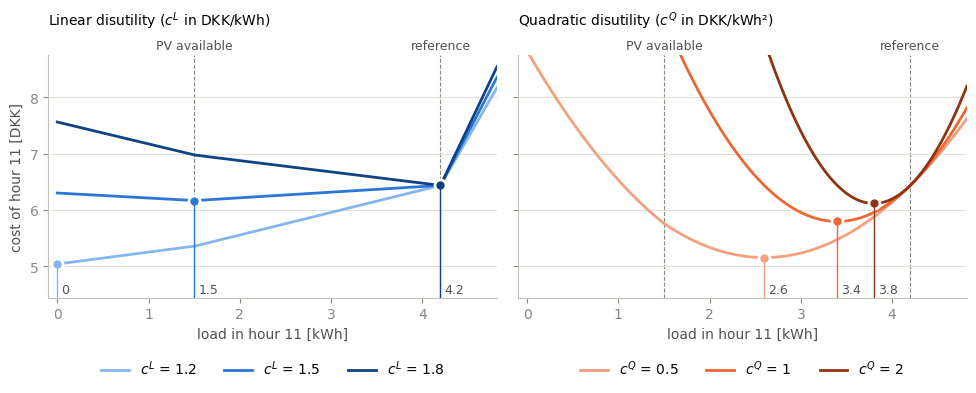

In [18]:
hour = 11
ref_h, pv_h = reference[hour], data_lin.pv_available[hour]
p_imp_h = data_lin.energy_price[hour] + data_lin.import_tariff
a_h = float(np.median([data_lin.energy_price[hour] - data_lin.export_tariff, data_lin.pv_marginal_cost, p_imp_h]))
load = np.round(np.arange(0, 1.15 * ref_h, 0.01), 2)
energy = a_h * np.minimum(load, pv_h) + p_imp_h * np.maximum(load - pv_h, 0)
curves = [
    ("Linear disutility ($c^L$ in DKK/kWh)", "$c^L$", BLUE_RAMP,
     {c: energy + c * np.abs(load - ref_h) for c in [1.2, 1.5, 1.8]}),
    ("Quadratic disutility ($c^Q$ in DKK/kWh²)", "$c^Q$", ORANGE_RAMP,
     {c: energy + c * (load - ref_h) ** 2 for c in [0.5, 1.0, 2.0]}),
]
low = min(cost.min() for *_, family in curves for cost in family.values())
high = max(cost.max() for cost in curves[0][3].values())

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for ax, (title, symbol, ramp, family) in zip(axes, curves):
    for x, label in ((pv_h, "PV available"), (ref_h, "reference")):
        ax.axvline(x, color=GREY, lw=0.8, ls="--", zorder=0)
        ax.text(x, high + 0.25, label, ha="center", va="bottom", color="#52514e", fontsize=9)
    for (c, cost), color in zip(family.items(), ramp):
        best = load[cost.argmin()]
        ax.plot(load, cost, color=color, label=f"{symbol} = {c:g}")
        ax.plot(best, cost.min(), "o", color=color, ms=8, mec="white", mew=2)
        ax.vlines(best, low - 0.6, cost.min(), color=color, lw=1)
        ax.annotate(f"{best:g}", (best, low - 0.6), xytext=(3, 3), textcoords="offset points",
                    color="#52514e", fontsize=9)
    ax.set_title(title, loc="left", fontsize=10, pad=22)
    ax.set(xlabel=f"load in hour {hour} [kWh]", xlim=(-0.1, load[-1]), ylim=(low - 0.6, high + 0.2))
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)
axes[0].set_ylabel(f"cost of hour {hour} [DKK]")
fig.tight_layout()
#fig.savefig(OUT_D / "q2d_hourly_objective.png", dpi=150)


In [20]:
c_lin, c_quad = PAIRS["base"]
factors = [0.9, 0.98, 1.0, 1.1, 1.5]
sensitivity = pd.DataFrame({
    "linear_disutility_kWh": [LinearDisutilityModel(replace(data_lin, linear_disutility=f * c_lin))
                              .build().solve().hourly["load"].sum() for f in factors],
    "quadratic_disutility_kWh": [QuadraticDisutilityModel(replace(data_quad, quadratic_disutility=f * c_quad))
                                 .build().solve().hourly["load"].sum() for f in factors],
}, index=pd.Index(factors, name="coefficient_relative_to_base")).round(3)
#sensitivity.to_csv(OUT_D / "q2d_sensitivity.csv")

base_lin, base_quad = next(iter(pair_loads.values()))
lin_row, quad_row = table_d.iloc[1], table_d.iloc[2]
crossed_lin = lin_row.procurement_DKK + c_quad * ((reference - base_lin) ** 2).sum()
crossed_quad = quad_row.procurement_DKK + c_lin * np.abs(reference - base_quad).sum()
print(f"linear schedule under quadratic preferences: {crossed_lin:.2f} DKK (optimum {quad_row.total_DKK:.2f})")
print(f"quadratic schedule under linear preferences: {crossed_quad:.2f} DKK (optimum {lin_row.total_DKK:.2f})")

nested = replace(data_lin, reference_load=np.full(len(reference), data_lin.load_max_kWh),
                 linear_disutility=data_q1.consumption_utility)
gap_q1 = np.abs(LinearDisutilityModel(nested).build().solve().hourly["load"] - res_q1.hourly["load"]).max()
print(f"largest load difference, Question 1 against linear disutility with reference L_max: {gap_q1:.1e} kWh")
sensitivity


linear schedule under quadratic preferences: 49.45 DKK (optimum 39.97)
quadratic schedule under linear preferences: 46.24 DKK (optimum 44.31)
largest load difference, Question 1 against linear disutility with reference L_max: 0.0e+00 kWh


,linear_disutility_kWh,quadratic_disutility_kWh
coefficient_relative_to_base,,
0.90,0.00,21.858
0.98,0.00,22.587
1.00,23.10,22.765
1.10,23.58,23.559
1.50,32.34,25.687


## Extra Plots for Q3 e) Minimum Daily Energy

In [ ]:
import sys
sys.path.append('..')

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import src
from src.data_loader import load_question
from src.model_q2 import QuadraticDisutilityModel
from src.model_q3 import MinEnergyModel

OUT_3 = Path(src.__file__).resolve().parents[1] / "results" / "Q3"
OUT_3.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, GREEN, VIOLET = "#2a78d6", "#eb6834", "#008300", "#4a3aa7"
INK, GREY = "#0b0b0b", "#898781"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "xtick.color": GREY, "ytick.color": GREY,
    "axes.labelcolor": "#52514e", "lines.linewidth": 2, "legend.frameon": False,
})

data_3 = load_question("Q3")
res_3 = MinEnergyModel(data_3).build().solve()
res_2c = QuadraticDisutilityModel(data_3).build().solve()
hr_3, hr_2c = res_3.hourly, res_2c.hourly
hours = hr_3.index.to_numpy()
mu = res_3.duals["min_energy"]

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))

ax.bar(hours - 0.2, hr_2c["load"], width=0.4, color=GREY, alpha=0.6,
       label=f"without requirement, Q2.(c) ({hr_2c['load'].sum():.1f} kWh)")
ax.bar(hours + 0.2, hr_3["load"], width=0.4, color=BLUE,
       label=f"with requirement ({hr_3['load'].sum():.1f} kWh)")
ax.step(hours, hr_3["reference_load"], where="mid", color=INK, lw=1.5,
        label=f"reference load ({hr_3['reference_load'].sum():.1f} kWh)")
ax.step(hours, hr_3["pv_available"], where="mid", color=ORANGE, label="PV available")
ax.set(xlabel="hour", ylabel="kWh/h", xticks=hours, xlim=(-0.6, 23.6), ylim=(0, 6.4),
       title=f"Minimum daily energy, base case ($E^{{min}}$ = {data_3.min_daily_energy_kWh:g} kWh, $c^Q$ = {data_3.quadratic_disutility:g} DKK/kWh²)")
ax.legend(ncol=2, loc="upper left")

fig.tight_layout()
fig.savefig(OUT_3 / "q3e_base_case.png", dpi=150)

In [ ]:
above_2c = (hr_2c["load"] - hr_2c["reference_load"]).clip(lower=0)
above_3 = (hr_3["load"] - hr_3["reference_load"]).clip(lower=0)
summary_3 = pd.DataFrame({
    "without_requirement": [hr_2c["load"].sum(), hr_2c["pv"].sum(), hr_2c["import"].sum(), hr_2c["export"].sum(), res_2c.objective, above_2c.sum(), (above_2c > 1e-6).sum()],
    "with_requirement": [hr_3["load"].sum(), hr_3["pv"].sum(), hr_3["import"].sum(), hr_3["export"].sum(), res_3.objective, above_3.sum(), (above_3 > 1e-6).sum()],
}, index=["load_kWh", "pv_kWh", "import_kWh", "export_kWh", "objective_DKK", "above_reference_kWh", "hours_above_reference"])
print(f"mu = {mu:.4f} DKK/kWh")
summary_3.round(2)

## Extra Plots for Q3 f) Sensitivity Analysis

In [ ]:
import sys
sys.path.append('..')

from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import src
from src.data_loader import load_question
from src.model_q3 import MinEnergyModel

OUT_3 = Path(src.__file__).resolve().parents[1] / "results" / "Q3"
OUT_3.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, GREEN, VIOLET = "#2a78d6", "#eb6834", "#008300", "#4a3aa7"
INK, GREY = "#0b0b0b", "#898781"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "xtick.color": GREY, "ytick.color": GREY,
    "axes.labelcolor": "#52514e", "lines.linewidth": 2, "legend.frameon": False,
})


def run_3(data):
    """Solve the Question 3 model for one InputData and return (results, metrics in kWh and DKK)."""
    res = MinEnergyModel(data).build().solve()
    h = res.hourly
    dev = h["load"] - h["reference_load"]
    return res, {
        "energy_kWh": h["load"].sum(),
        "mu_DKK_per_kWh": res.duals["min_energy"],
        "objective_DKK": res.objective,
        "above_reference_kWh": dev.clip(lower=0).sum(),
        "below_reference_kWh": (-dev).clip(lower=0).sum(),
        "hours_above_reference": int((dev > 1e-6).sum()),
        "max_above_reference_kWh": dev.max(),
        "hours_at_max_load": int((h["load"] >= data.load_max_kWh - 1e-6).sum()),
    }


data_3 = load_question("Q3")
hours = data_3.hours
total_ref = round(float(data_3.reference_load.sum()), 2)
free_energy = round(float(run_3(replace(data_3, min_daily_energy_kWh=0.0))[1]["energy_kWh"]), 2)
total_ref, free_energy

In [ ]:
e_values = sorted(set(np.arange(0.0, 145.0, 1.0)) | {free_energy, total_ref})
sweep_e = pd.DataFrame({e: run_3(replace(data_3, min_daily_energy_kWh=float(e)))[1] for e in e_values}).T
sweep_e.index.name = "E_min"

fig, ax = plt.subplots(figsize=(9, 4.6))

ax.plot(sweep_e.index, sweep_e["objective_DKK"], color=BLUE, label="daily cost (bill + disutility)")
ax.axvline(free_energy, color=GREY, ls="--", lw=1.2, label=f"consumption without requirement ({free_energy:g} kWh)")
ax.axvline(total_ref, color=INK, ls="--", lw=1.2, label=f"total reference load ({total_ref:g} kWh)")
ax.axvline(data_3.min_daily_energy_kWh, color=ORANGE, ls=":", lw=1.5, label=f"base case ({data_3.min_daily_energy_kWh:g} kWh)")
ax.set(xlabel="$E^{min}$ [kWh]", ylabel="DKK", xlim=(0, 144),
       title=f"Sensitivity to the minimum daily energy ($c^Q$ = {data_3.quadratic_disutility:g} DKK/kWh²)")
fig.legend(*ax.get_legend_handles_labels(), loc="lower center", ncol=2)

fig.tight_layout(rect=(0, 0.14, 1, 1))
fig.savefig(OUT_3 / "q3f_emin_sweep.png", dpi=150)

In [ ]:
sweep_e.loc[[0.0, free_energy, 25.0, 30.0, total_ref, 35.0, 40.0, 50.0, 60.0, 80.0, 100.0, 120.0, 144.0]].round(2)

In [ ]:
c_values = [0.1, 1.0, 10.0]
runs_c = {c: run_3(replace(data_3, quadratic_disutility=c)) for c in c_values}

fig, ax = plt.subplots(figsize=(9, 4))

ax.step(hours, data_3.reference_load, where="mid", color=INK, lw=1.5, label=f"reference load ({total_ref:g} kWh)")
for (c, (res, _)), color in zip(runs_c.items(), [ORANGE, BLUE, GREEN]):
    ax.step(hours, res.hourly["load"], where="mid", color=color, label=f"optimal load, $c^Q$ = {c:g} DKK/kWh²")
ax.set(xlabel="hour", ylabel="kWh/h", xticks=hours, xlim=(-0.6, 23.6), ylim=(0, 6.4),
       title=f"Sensitivity to the disutility coefficient ($E^{{min}}$ = {data_3.min_daily_energy_kWh:g} kWh)")
ax.legend(loc="upper left")

fig.tight_layout()
fig.savefig(OUT_3 / "q3f_cq_profiles.png", dpi=150)

In [ ]:
pd.DataFrame({c: run_3(replace(data_3, quadratic_disutility=c))[1] for c in [0.05, 0.1, 0.2, 0.5, 1.0, 2.0, 5.0, 10.0, 50.0]}).T.round(2)

## Extra Plots for Q3 g) iv Battery Base Case

In [ ]:
import sys
sys.path.append('..')

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import src
from src.data_loader import load_question
from src.model_q3 import MinEnergyModel, BatteryModel

OUT_3B = Path(src.__file__).resolve().parents[1] / "results" / "Q3_battery"
OUT_3B.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, GREEN, VIOLET = "#2a78d6", "#eb6834", "#008300", "#4a3aa7"
INK, GREY = "#0b0b0b", "#898781"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "xtick.color": GREY, "ytick.color": GREY,
    "axes.labelcolor": "#52514e", "lines.linewidth": 2, "legend.frameon": False,
})


def summary_3(res, data):
    """Daily totals of one Question 3 run, in kWh and DKK (bill = procurement + PV cost)."""
    h = res.hourly
    dev = h["load"] - h["reference_load"]
    disutility = (data.quadratic_disutility * dev ** 2).sum()
    return {
        "load_kWh": h["load"].sum(),
        "pv_kWh": h["pv"].sum(),
        "import_kWh": h["import"].sum(),
        "export_kWh": h["export"].sum(),
        "above_reference_kWh": dev.clip(lower=0).sum(),
        "hours_above_reference": (dev > 1e-6).sum(),
        "bill_DKK": res.objective - disutility,
        "disutility_DKK": disutility,
        "objective_DKK": res.objective,
        "mu_DKK_per_kWh": res.duals["min_energy"],
    }


data_nb = load_question("Q3")
data_b = load_question("Q3_battery")
res_nb = MinEnergyModel(data_nb).build().solve()
res_b = BatteryModel(data_b).build().solve()
hr_b = res_b.hourly
hours = hr_b.index.to_numpy()
p_imp = data_b.energy_price + data_b.import_tariff
p_exp = data_b.energy_price - data_b.export_tariff

In [ ]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6.2), sharex=True, height_ratios=[3, 2])

ax1.bar(hours, hr_b["charge"], width=0.6, color=GREEN, label="charging")
ax1.bar(hours, -hr_b["discharge"], width=0.6, color=ORANGE, label="discharging")
ax1.step(hours, hr_b["soc"], where="mid", color=BLUE, label="state of charge (end of hour)")
ax1.axhline(0, color=GREY, lw=0.8)
ax1.set(ylabel="kWh", ylim=(-2, 4.6),
        title=f"Battery, base case ({data_b.battery_capacity_kWh:g} kWh, {data_b.battery_max_charge_kW:g} kW, efficiency {data_b.battery_charging_efficiency:g})")
ax1.legend(ncol=3, loc="upper left")

ax2.fill_between(hours, p_exp, p_imp, step="mid", color=GREY, alpha=0.15, lw=0,
                 label="export price (lower edge) to import price (upper edge)")
ax2.step(hours, p_imp, where="mid", color=GREY, lw=1.2)
ax2.step(hours, p_exp, where="mid", color=GREY, lw=1.2)
ax2.set(xlabel="hour", ylabel="DKK/kWh", xticks=hours, xlim=(-0.6, 23.6), ylim=(0, 3.6))
ax2.legend(loc="upper left")

fig.tight_layout()
fig.savefig(OUT_3B / "q3g_battery_base_case.png", dpi=150)

In [ ]:
overlap = ((hr_b["charge"] > 1e-6) & (hr_b["discharge"] > 1e-6)).sum()
print(f"value of the battery = {res_nb.objective - res_b.objective:.2f} DKK/day | hours with charging and discharging: {overlap}")
print(f"charging hours: {hours[hr_b['charge'] > 1e-6].tolist()} | discharging hours: {hours[hr_b['discharge'] > 1e-6].tolist()}")
print(f"largest change in hourly load: {(hr_b['load'] - res_nb.hourly['load']).abs().max():.2f} kWh")
pd.DataFrame({"without_battery": summary_3(res_nb, data_nb), "with_battery": summary_3(res_b, data_b)}).round(2)

## Extra Plots for Q3 g) v Battery Value Sensitivity

In [ ]:
import sys
sys.path.append('..')

from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import src
from src.data_loader import load_question
from src.model_q3 import MinEnergyModel, BatteryModel
from src.scenarios import scale_prices

OUT_3B = Path(src.__file__).resolve().parents[1] / "results" / "Q3_battery"
OUT_3B.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, GREEN, VIOLET = "#2a78d6", "#eb6834", "#008300", "#4a3aa7"
INK, GREY = "#0b0b0b", "#898781"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "xtick.color": GREY, "ytick.color": GREY,
    "axes.labelcolor": "#52514e", "lines.linewidth": 2, "legend.frameon": False,
})


def battery_value(data):
    """Value of the battery (DKK/day): cost without battery minus cost with battery, on the same data, and the net energy discharged (kWh)."""
    res_b = BatteryModel(data).build().solve()
    return {
        "value_DKK": MinEnergyModel(data).build().solve().objective - res_b.objective,
        "net_discharged_kWh": (res_b.hourly["discharge"] - res_b.hourly["charge"]).clip(lower=0).sum(),
    }


data_b = load_question("Q3_battery")

In [ ]:
spreads = [0.0, 0.5, 1.0, 1.5, 2.0, 3.0]
capacities = [1.0, 2.0, 4.0, 8.0, 12.0, 20.0]
efficiencies = [0.7, 0.8, 0.85, 0.9, 0.95, 1.0]

sweep_spread = pd.DataFrame({f: battery_value(scale_prices(data_b, f, keep_mean=True)) for f in spreads}).T
sweep_capacity = pd.DataFrame({c: battery_value(replace(data_b, battery_capacity_kWh=c, battery_initial_soc_kWh=0.5 * c)) for c in capacities}).T
sweep_efficiency = pd.DataFrame({e: battery_value(replace(data_b, battery_charging_efficiency=e, battery_discharging_efficiency=e)) for e in efficiencies}).T
sweep_spread.index.name, sweep_capacity.index.name, sweep_efficiency.index.name = "price_spread_factor", "capacity_kWh", "efficiency"

fig, axes = plt.subplots(1, 3, figsize=(10, 3.6), sharey=True)
panels = [(sweep_spread, 1.0, "price spread (× base case, same mean)", BLUE),
          (sweep_capacity, data_b.battery_capacity_kWh, "battery capacity [kWh]", GREEN),
          (sweep_efficiency, data_b.battery_charging_efficiency, "efficiency (charging = discharging)", VIOLET)]
for ax, (sweep, base, xlabel, color) in zip(axes, panels):
    ax.plot(sweep.index, sweep["value_DKK"], "o-", color=color)
    ax.axvline(base, color=ORANGE, ls=":", lw=1.5)
    ax.set(xlabel=xlabel)
axes[0].set(ylabel="value of the battery [DKK/day]")
fig.suptitle("Value of the battery (dotted line: base case)")

fig.tight_layout()
fig.savefig(OUT_3B / "q3g_battery_value_sensitivity.png", dpi=150)

In [ ]:
print(sweep_spread.round(2) + 0.0, "\n")
print(sweep_capacity.round(2) + 0.0, "\n")
print(sweep_efficiency.round(2) + 0.0)